In [2]:

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from scipy.ndimage import binary_dilation

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader, Subset
from pathlib import Path
import joblib


In [3]:
DATA_PATH = Path(
    r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\data\TerraSpectra_Synthetic_Demo_Dataset\synthetic_hsi_demo.npz"
)

data = np.load(DATA_PATH)

cube = data["cube"]
labels = data["labels"]
wavelengths = data["wavelengths_nm"]

In [4]:
print("Hyperspectral cube shape:", cube.shape)
print("Labels shape:", labels.shape)
print("Number of spectral bands:", len(wavelengths))

print("Unique labels:", np.unique(labels))

Hyperspectral cube shape: (32, 32, 16)
Labels shape: (32, 32)
Number of spectral bands: 16
Unique labels: [0 1]


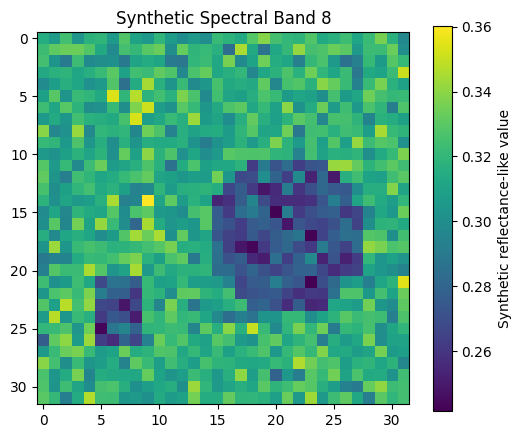

In [5]:
plt.figure(figsize=(6, 5))

plt.imshow(cube[:, :, 7], cmap="viridis")
plt.title("Synthetic Spectral Band 8")
plt.colorbar(label="Synthetic reflectance-like value")

plt.show()

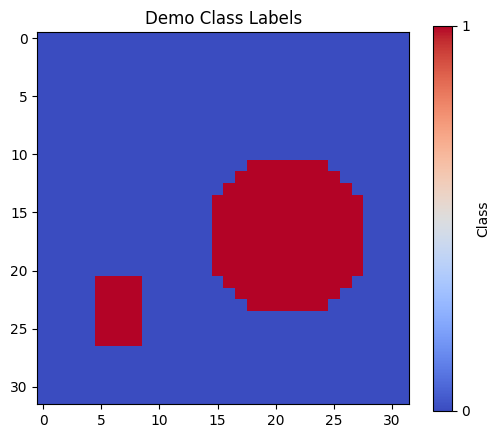

In [6]:
plt.figure(figsize=(6, 5))

plt.imshow(labels, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Demo Class Labels")
plt.colorbar(ticks=[0, 1], label="Class")

plt.show()

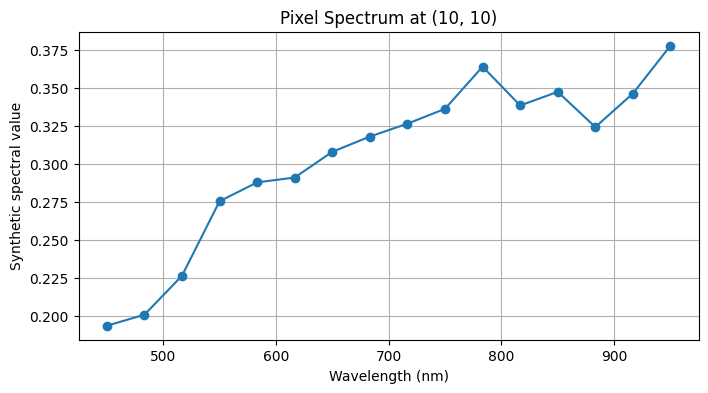

In [7]:
row = 10
col = 10

spectrum = cube[row, col, :]

plt.figure(figsize=(8, 4))

plt.plot(wavelengths, spectrum, marker="o")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Synthetic spectral value")
plt.title(f"Pixel Spectrum at ({row}, {col})")
plt.grid(True)

plt.show()

In [8]:
csv_path = DATA_PATH.parent / "pixel_spectra.csv"

df = pd.read_csv(csv_path)

df.head()

,row,col,label,class_name,band_01,band_02,band_03,band_04,band_05,band_06,band_07,band_08,band_09,band_10,band_11,band_12,band_13,band_14,band_15,band_16
0,0,0,0,healthy_demo,0.185869,0.196336,0.243337,0.269057,0.254921,0.279858,0.310529,0.315177,0.325640,0.320079,0.343874,0.345257,0.340012,0.357773,0.357493,0.352457
1,0,1,0,healthy_demo,0.163611,0.212262,0.226637,0.248457,0.263067,0.303059,0.300045,0.306736,0.314521,0.329608,0.330612,0.333781,0.337294,0.362851,0.339910,0.349527
2,0,2,0,healthy_demo,0.189126,0.221886,0.232486,0.247211,0.267962,0.302813,0.317436,0.325011,0.317378,0.332623,0.334244,0.338070,0.349199,0.346452,0.359552,0.363102
3,0,3,0,healthy_demo,0.184801,0.186343,0.225509,0.247139,0.265681,0.287196,0.321947,0.303595,0.332474,0.305134,0.324316,0.332890,0.341267,0.347794,0.356416,0.353597
4,0,4,0,healthy_demo,0.183121,0.197133,0.209635,0.234783,0.257913,0.292062,0.301316,0.317870,0.311327,0.322830,0.331441,0.322823,0.335313,0.326916,0.338138,0.348800


In [9]:
# avalabality 
print(df.columns)
print(df.shape)

Index(['row', 'col', 'label', 'class_name', 'band_01', 'band_02', 'band_03',
       'band_04', 'band_05', 'band_06', 'band_07', 'band_08', 'band_09',
       'band_10', 'band_11', 'band_12', 'band_13', 'band_14', 'band_15',
       'band_16'],
      dtype='object')
(1024, 20)


In [10]:
print("Cube shape:", cube.shape)
print("Labels shape:", labels.shape)

assert cube.shape == (32, 32, 16)
assert labels.shape == (32, 32)

print("Unique labels:", np.unique(labels))

Cube shape: (32, 32, 16)
Labels shape: (32, 32)
Unique labels: [0 1]


In [11]:
unique, counts = np.unique(labels, return_counts=True)

for label, count in zip(unique, counts):
    print(f"Class {label}: {count} pixels")

Class 0: 855 pixels
Class 1: 169 pixels


In [12]:
X = cube.reshape(-1, 16)
y = labels.reshape(-1)



# STEP 1: Check spatial class distribution

print("\n--- Spatial Class Distribution ---")

for row in range(labels.shape[0]):
    healthy = np.sum(labels[row, :] == 0)
    stress = np.sum(labels[row, :] == 1)

    print(
        f"Row {row:02d} | "
        f"Healthy: {healthy:02d} | "
        f"Stress: {stress:02d}"
    )

print("\n--- Overall Distribution ---")

unique, counts = np.unique(labels, return_counts=True)

for label, count in zip(unique, counts):
    class_name = "Healthy" if label == 0 else "Stress"
    print(f"{class_name}: {count}")


print("X:", X.shape)
print("y:", y.shape)


--- Spatial Class Distribution ---
Row 00 | Healthy: 32 | Stress: 00
Row 01 | Healthy: 32 | Stress: 00
Row 02 | Healthy: 32 | Stress: 00
Row 03 | Healthy: 32 | Stress: 00
Row 04 | Healthy: 32 | Stress: 00
Row 05 | Healthy: 32 | Stress: 00
Row 06 | Healthy: 32 | Stress: 00
Row 07 | Healthy: 32 | Stress: 00
Row 08 | Healthy: 32 | Stress: 00
Row 09 | Healthy: 32 | Stress: 00
Row 10 | Healthy: 32 | Stress: 00
Row 11 | Healthy: 25 | Stress: 07
Row 12 | Healthy: 23 | Stress: 09
Row 13 | Healthy: 21 | Stress: 11
Row 14 | Healthy: 19 | Stress: 13
Row 15 | Healthy: 19 | Stress: 13
Row 16 | Healthy: 19 | Stress: 13
Row 17 | Healthy: 19 | Stress: 13
Row 18 | Healthy: 19 | Stress: 13
Row 19 | Healthy: 19 | Stress: 13
Row 20 | Healthy: 19 | Stress: 13
Row 21 | Healthy: 17 | Stress: 15
Row 22 | Healthy: 19 | Stress: 13
Row 23 | Healthy: 21 | Stress: 11
Row 24 | Healthy: 28 | Stress: 04
Row 25 | Healthy: 28 | Stress: 04
Row 26 | Healthy: 28 | Stress: 04
Row 27 | Healthy: 32 | Stress: 00
Row 28 | Hea

In [13]:

# STEP 1B: Display complete spatial label map

print("\n--- Complete 32x32 Label Map ---")
print("H = Healthy | S = Stress\n")

for row in range(labels.shape[0]):
    row_map = ""

    for col in range(labels.shape[1]):
        if labels[row, col] == 0:
            row_map += "H "
        else:
            row_map += "S "

    print(f"Row {row:02d}: {row_map}")

print("\n--- Remaining Row Distribution ---")

for row in range(23, labels.shape[0]):
    healthy = np.sum(labels[row, :] == 0)
    stress = np.sum(labels[row, :] == 1)

    print(
        f"Row {row:02d} | "
        f"Healthy: {healthy:02d} | "
        f"Stress: {stress:02d}"
    )



--- Complete 32x32 Label Map ---
H = Healthy | S = Stress

Row 00: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 01: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 02: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 03: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 04: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 05: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 06: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 07: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 08: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 09: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 10: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 11: H H H H H H H H H H H H H H H H H H S S S S S S S H H H H H H H 
Row 12: H H H H H H H H H H H H H H H H H S S S S S S S S S H H 

In [14]:

# STEP 1D: Spatial Train-Test Split

height, width = labels.shape

# Flattened pixel features for Random Forest
X = cube.reshape(-1, cube.shape[2])
y = labels.reshape(-1)

# Create spatial masks
test_mask = np.zeros((height, width), dtype=bool)
buffer_mask = np.zeros((height, width), dtype=bool)

# Testing region: rows 20-25, columns 15-26
test_mask[20:26, 15:27] = True

# Buffer region: 2-pixel separation
buffer_mask[18:28, 13:29] = True

# Training region: outside buffer
train_mask = ~buffer_mask

# Convert masks to flattened indices
train_indices = np.flatnonzero(train_mask.ravel())
test_indices = np.flatnonzero(test_mask.ravel())

# Extract train and test data
X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

# Display split information
print("\n--- Spatial Split Results ---")

print("Training pixels:", len(train_indices))
print("Testing pixels:", len(test_indices))
print("Excluded buffer pixels:", np.sum(buffer_mask) - len(test_indices))

print("\nTraining class distribution:")
print(np.unique(y_train, return_counts=True))

print("\nTesting class distribution:")
print(np.unique(y_test, return_counts=True))

# Verify both classes exist
assert len(np.unique(y_train)) == 2, "Training set must contain both classes"
assert len(np.unique(y_test)) == 2, "Testing set must contain both classes"

print("\nSpatial split created successfully!")



--- Spatial Split Results ---
Training pixels: 864
Testing pixels: 72
Excluded buffer pixels: 88

Training class distribution:
(array([0, 1], dtype=uint8), array([761, 103]))

Testing class distribution:
(array([0, 1], dtype=uint8), array([33, 39]))

Spatial split created successfully!


# save the splited datset

In [ ]:

# import os
# import numpy as np

# # Create dataset directory
# os.makedirs(r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\data\processed\saved_datasets", exist_ok=True)

# # Save spatially split dataset
# np.savez_compressed(
#     r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\data\processed\saved_datasets\terraspectra_spatial_dataset.npz",
#     X_train=X_train,
#     X_test=X_test,
#     y_train=y_train,
#     y_test=y_test,
#     train_indices=train_indices,
#     test_indices=test_indices,
#     train_mask=train_mask,
#     test_mask=test_mask,
#     buffer_mask=buffer_mask
# )

# print("Spatial training dataset saved successfully!")
# print("Location: saved_datasets/terraspectra_spatial_dataset.npz")


Spatial training dataset saved successfully!
Location: saved_datasets/terraspectra_spatial_dataset.npz


In [ ]:

# STEP 2A: Verify spatial split and CNN patch separation

from scipy.ndimage import binary_dilation

# Check class distribution
print("\n--- Training Class Counts ---")
print("Healthy:", np.sum(y_train == 0))
print("Stress:", np.sum(y_train == 1))

print("\n--- Testing Class Counts ---")
print("Healthy:", np.sum(y_test == 0))
print("Stress:", np.sum(y_test == 1))

# Check that training and testing masks do not overlap
assert not np.any(train_mask & test_mask)

# Verify that 3x3 patches cannot overlap
train_patch_area = binary_dilation(
    train_mask, structure=np.ones((3, 3), dtype=bool)
)

test_patch_area = binary_dilation(
    test_mask, structure=np.ones((3, 3), dtype=bool)
)

patch_overlap = np.any(train_patch_area & test_patch_area)

print("\n--- CNN Spatial Leakage Check ---")
print("Training/testing patch overlap:", patch_overlap)

assert not patch_overlap, "CNN spatial leakage detected!"

print("\nSpatial split verification completed!")






--- Training Class Counts ---
Healthy: 761
Stress: 103

--- Testing Class Counts ---
Healthy: 33
Stress: 39

--- CNN Spatial Leakage Check ---
Training/testing patch overlap: False

Spatial split verification completed!


# Traning RF Classsifiere

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)


In [ ]:

# STEP 4: Evaluate 3D-CNN on spatial test pixels

model.eval()

cnn_predictions = []
cnn_true_labels = []
cnn_probabilities = []

with torch.no_grad():

    for patches, targets in test_loader:

        patches = patches.to(device)

        outputs = model(patches)

        probabilities = torch.softmax(
            outputs, dim=1
        )

        predictions = outputs.argmax(dim=1)

        cnn_predictions.extend(
            predictions.cpu().numpy()
        )

        cnn_true_labels.extend(
            targets.numpy()
        )

        cnn_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

cnn_predictions = np.array(cnn_predictions)
cnn_true_labels = np.array(cnn_true_labels)
cnn_probabilities = np.array(cnn_probabilities)

# Verify identical test labels
assert np.array_equal(cnn_true_labels, y_test)

# Confusion matrix
cnn_cm = confusion_matrix(
    y_test,
    cnn_predictions,
    labels=[0, 1]
)

print("\n--- 3D-CNN Confusion Matrix ---")
print(cnn_cm)

print("\n--- 3D-CNN Classification Report ---")

print(
    classification_report(
        y_test,
        cnn_predictions,
        labels=[0, 1],
        target_names=["Healthy", "Stress"],
        zero_division=0
    )
)

cnn_accuracy = accuracy_score(
    y_test, cnn_predictions
)

cnn_precision = precision_score(
    y_test, cnn_predictions,
    pos_label=1, zero_division=0
)

cnn_recall = recall_score(
    y_test, cnn_predictions,
    pos_label=1, zero_division=0
)

cnn_f1 = f1_score(
    y_test, cnn_predictions,
    pos_label=1, zero_division=0
)

print("Accuracy:", cnn_accuracy)
print("Stress Precision:", cnn_precision)
print("Stress Recall:", cnn_recall)
print("Stress F1-score:", cnn_f1)



--- 3D-CNN Confusion Matrix ---
[[26  7]
 [ 0 39]]

--- 3D-CNN Classification Report ---
              precision    recall  f1-score   support

     Healthy       1.00      0.79      0.88        33
      Stress       0.85      1.00      0.92        39

    accuracy                           0.90        72
   macro avg       0.92      0.89      0.90        72
weighted avg       0.92      0.90      0.90        72

Accuracy: 0.9027777777777778
Stress Precision: 0.8478260869565217
Stress Recall: 1.0
Stress F1-score: 0.9176470588235294


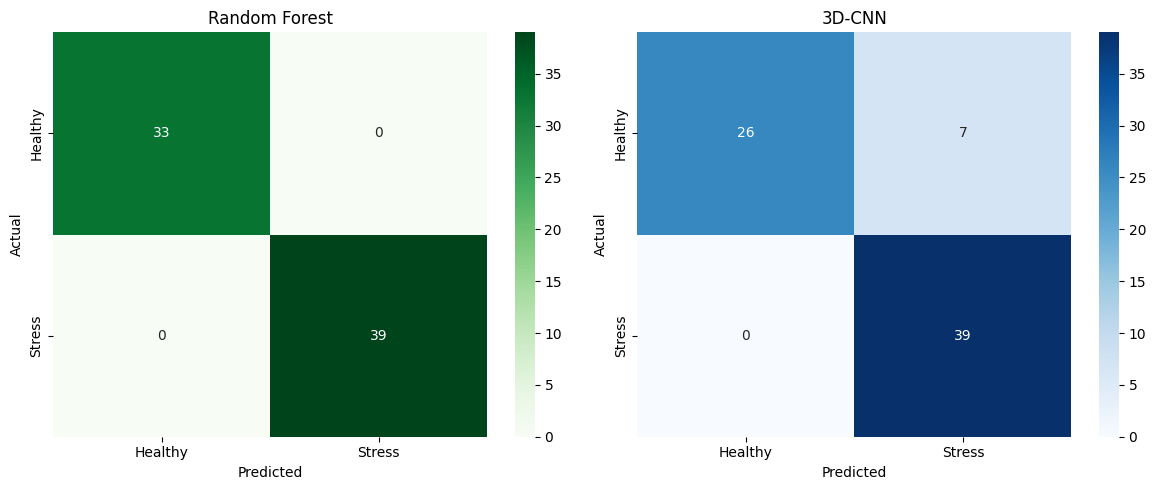

In [ ]:

# STEP 5: Visualize confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Healthy", "Stress"],
    yticklabels=["Healthy", "Stress"],a
    ax=axes[0]
)

axes[0].set_title("Random Forest")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Healthy", "Stress"],
    yticklabels=["Healthy", "Stress"],
    ax=axes[1]
)

axes[1].set_title("3D-CNN")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()

evaluation_dir = Path(r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\evaluation")
evaluation_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    evaluation_dir / "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# STEP 6: Save model comparison

comparison = pd.DataFrame({
    "Model": ["Random Forest", "3D-CNN"],
    "Accuracy": [rf_accuracy, cnn_accuracy],
    "Precision": [rf_precision, cnn_precision],
    "Recall": [rf_recall, cnn_recall],
    "F1_Score": [rf_f1, cnn_f1]
})

comparison.to_csv(
    evaluation_dir / "model_comparison.csv",
    index=False
)

print("\n--- MODEL COMPARISON ---")
print(comparison.to_string(index=False))



--- MODEL COMPARISON ---
        Model  Accuracy  Precision  Recall  F1_Score
Random Forest  1.000000   1.000000     1.0  1.000000
       3D-CNN  0.902778   0.847826     1.0  0.917647


In [ ]:
artifact_dir = Path(r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    rf_model,
    artifact_dir / "random_forest_baseline.joblib"
)

['E:\\internhips\\infotact solutions\\TerraSpectra Hyperspectral Crop Disease Forecasting\\backend\\artifacts\\random_forest_baseline.joblib']

In [ ]:

import torch
from torch.utils.data import Dataset

class HyperspectralDataset(Dataset):

    def __init__(self, cube, labels, patch_size=3):
        self.cube = torch.tensor(
            cube, dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels, dtype=torch.long
        )

        self.patch_size = patch_size
        self.pad = patch_size // 2

        self.cube = torch.nn.functional.pad(
            self.cube.permute(2, 0, 1).unsqueeze(0),
            (self.pad, self.pad, self.pad, self.pad),
            mode="reflect"
        ).squeeze(0).permute(1, 2, 0)

    def __len__(self):
        return self.labels.shape[0] * self.labels.shape[1]

    def __getitem__(self, idx):

        height, width = self.labels.shape

        row = idx // width
        col = idx % width

        patch = self.cube[
            row:row + self.patch_size,
            col:col + self.patch_size,
            :
        ]

        patch = patch.permute(2, 0, 1)

        patch = patch.unsqueeze(0)

        label = self.labels[row, col]

        return patch, label


# Data loaders

In [ ]:
from torch.utils.data import DataLoader, Subset
import numpy as np

dataset = HyperspectralDataset(cube, labels)


# STEP 3: Create CNN loaders using spatial indices

dataset = HyperspectralDataset(cube, labels)

train_dataset = Subset(
    dataset,
    train_indices.tolist()
)

test_dataset = Subset(
    dataset,
    test_indices.tolist()
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("CNN training samples:", len(train_dataset))
print("CNN testing samples:", len(test_dataset))

CNN training samples: 864
CNN testing samples: 72


In [ ]:
patches, targets = next(iter(train_loader))

print("Batch:", patches.shape)
print("Labels:", targets.shape)

Batch: torch.Size([16, 1, 16, 3, 3])
Labels: torch.Size([16])


# Build and train the 3D-CNN

In [123]:

import torch
import torch.nn as nn

class HyperspectralCNN(nn.Module):

    def __init__(self, num_classes=2):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv3d(
                1, 16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv3d(
                16, 32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.AdaptiveAvgPool3d((1, 1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x


configure traning

In [124]:

# Calculate class weights from training labels only

class_counts = np.bincount(
    y_train,
    minlength=2
)

class_weights = len(y_train) / (
    2 * np.maximum(class_counts, 1)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print("Training class counts:", class_counts)
print("Class weights:", class_weights)


Training class counts: [761 103]
Class weights: tensor([0.5677, 4.1942])


tring loop

In [125]:
epochs = 20

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for patches, targets in train_loader:

        patches = patches.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(patches)

        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    accuracy = correct / total

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {total_loss / len(train_loader):.4f} | "
        f"Accuracy: {accuracy:.4f}"
    )

Epoch 1/20 | Loss: 0.1869 | Accuracy: 0.9444
Epoch 2/20 | Loss: 0.0895 | Accuracy: 0.9838
Epoch 3/20 | Loss: 0.0886 | Accuracy: 0.9664
Epoch 4/20 | Loss: 0.0750 | Accuracy: 0.9815
Epoch 5/20 | Loss: 0.0537 | Accuracy: 0.9896
Epoch 6/20 | Loss: 0.0716 | Accuracy: 0.9815
Epoch 7/20 | Loss: 0.0469 | Accuracy: 0.9907
Epoch 8/20 | Loss: 0.1708 | Accuracy: 0.9387
Epoch 9/20 | Loss: 0.0659 | Accuracy: 0.9884
Epoch 10/20 | Loss: 0.0626 | Accuracy: 0.9792
Epoch 11/20 | Loss: 0.0732 | Accuracy: 0.9850
Epoch 12/20 | Loss: 0.0946 | Accuracy: 0.9653
Epoch 13/20 | Loss: 0.0838 | Accuracy: 0.9873
Epoch 14/20 | Loss: 0.0941 | Accuracy: 0.9815
Epoch 15/20 | Loss: 0.0511 | Accuracy: 0.9919
Epoch 16/20 | Loss: 0.0661 | Accuracy: 0.9792
Epoch 17/20 | Loss: 0.0415 | Accuracy: 0.9873
Epoch 18/20 | Loss: 0.0700 | Accuracy: 0.9826
Epoch 19/20 | Loss: 0.0515 | Accuracy: 0.9942
Epoch 20/20 | Loss: 0.0516 | Accuracy: 0.9861


In [126]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for patches, targets in test_loader:

        patches = patches.to(device)

        outputs = model(patches)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            targets.numpy()
        )

print(classification_report(
    all_targets,
    all_predictions,
    target_names=["Healthy", "Stress"]
))

              precision    recall  f1-score   support

     Healthy       1.00      0.79      0.88        33
      Stress       0.85      1.00      0.92        39

    accuracy                           0.90        72
   macro avg       0.92      0.89      0.90        72
weighted avg       0.92      0.90      0.90        72



In [127]:

import numpy as np
import torch
import torch.nn.functional as F

# Make sure the trained model is available
model.eval()
model.to(device)

# Your Week 1 hyperspectral cube
# Expected shape: (32, 32, 16)
print("Cube shape:", cube.shape)

height, width, bands = cube.shape

# Convert cube to tensor
cube_tensor = torch.tensor(
    cube,
    dtype=torch.float32
)

# Convert to [Bands, Height, Width]
cube_tensor = cube_tensor.permute(2, 0, 1)

# Add batch dimension
cube_tensor = cube_tensor.unsqueeze(0)

# Pad for 3x3 spatial patches
cube_tensor = F.pad(
    cube_tensor,
    (1, 1, 1, 1),
    mode="reflect"
)

# Prediction arrays
prediction_map = np.zeros(
    (height, width),
    dtype=np.uint8
)

confidence_map = np.zeros(
    (height, width),
    dtype=np.float32
)

# Predict every pixel
with torch.no_grad():

    for row in range(height):

        for col in range(width):

            # Extract 3x3 spatial patch
            patch = cube_tensor[
                :,
                :,
                row:row + 3,
                col:col + 3
            ]

            # Shape: [1, 1, 16, 3, 3]
            patch = patch.unsqueeze(0)

            patch = patch.to(device)

            # CNN prediction
            outputs = model(patch)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predicted_class = probabilities.argmax(
                dim=1
            ).item()

            stress_probability = probabilities[
                0, 1
            ].item()

            prediction_map[row, col] = predicted_class

            confidence_map[row, col] = stress_probability

print("Prediction map shape:", prediction_map.shape)
print("Confidence map shape:", confidence_map.shape)

print("Prediction completed!")


Cube shape: (32, 32, 16)
Prediction map shape: (32, 32)
Confidence map shape: (32, 32)
Prediction completed!


In [128]:

import os
import numpy as np

output_dir = r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\data\output"

os.makedirs(output_dir, exist_ok=True)

np.save(
    os.path.join(output_dir, "prediction_map.npy"),
    prediction_map
)

np.save(
    os.path.join(output_dir, "confidence_map.npy"),
    confidence_map
)

print("Prediction map saved successfully!")
print("Confidence map saved successfully!")


Prediction map saved successfully!
Confidence map saved successfully!


# visualization 

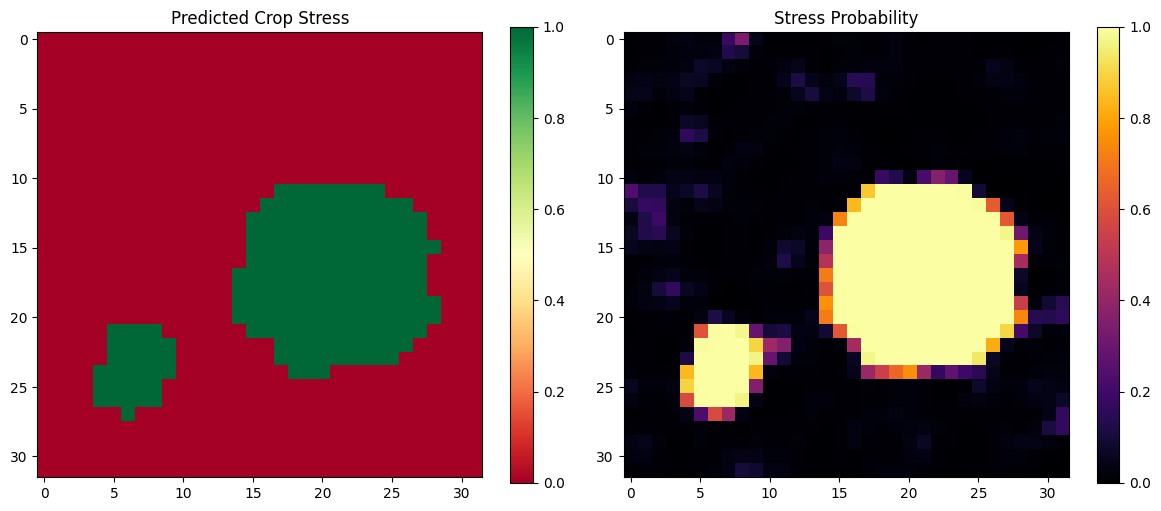

In [129]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    prediction_map,
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

plt.title("Predicted Crop Stress")
plt.colorbar()

plt.subplot(1, 2, 2)

plt.imshow(
    confidence_map,
    cmap="inferno",
    vmin=0,
    vmax=1
)

plt.title("Stress Probability")
plt.colorbar()

plt.tight_layout()
plt.show()


In [132]:
from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
from pathlib import Path

# ==========================================
# PREDICTION RELIABILITY EVALUATION
# ==========================================

models = {
    "Random Forest": rf_probabilities,
    "3D-CNN": cnn_probabilities
}

reliability_results = []

for name, probabilities in models.items():

    brier = brier_score_loss(y_test, probabilities)
    roc_auc = roc_auc_score(y_test, probabilities)
    pr_auc = average_precision_score(y_test, probabilities)

    reliability_results.append({
        "Model": name,
        "Brier_Score": brier,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc
    })

    print(f"\n{name}")
    print("-" * 35)
    print(f"Brier Score: {brier:.4f}")
    print(f"ROC-AUC:     {roc_auc:.4f}")
    print(f"PR-AUC:      {pr_auc:.4f}")

# Save CSV
evaluation_dir = Path(r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\evaluation")
evaluation_dir.mkdir(parents=True, exist_ok=True)

reliability_df = pd.DataFrame(reliability_results)

reliability_df.to_csv(
    evaluation_dir / "reliability_metrics.csv",
    index=False
)

print("\nReliability metrics saved successfully!")
print(reliability_df.to_string(index=False))


Random Forest
-----------------------------------
Brier Score: 0.0011
ROC-AUC:     1.0000
PR-AUC:      1.0000

3D-CNN
-----------------------------------
Brier Score: 0.0678
ROC-AUC:     1.0000
PR-AUC:      1.0000

Reliability metrics saved successfully!
        Model  Brier_Score  ROC_AUC  PR_AUC
Random Forest     0.001144      1.0     1.0
       3D-CNN     0.067755      1.0     1.0


In [130]:
import os

os.makedirs(r"backend\artifacts", exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_shape": [1, 16, 3, 3],
        "num_classes": 2,
        "class_names": ["Healthy", "Stress"]
    },
    r"backend\artifacts\terraspectra_cnn.pth"
)